In [2]:
#| include: false
# setup for the generated demo cells (AI-generated; see _notes/edit-index-2026-11-09.md)
import os, sys
_root = os.path.expanduser('~/Documents/Projects/equivalences')
if _root not in sys.path:
    sys.path.insert(0, _root)
import numpy as np
import matplotlib.pyplot as plt
import IPython.display as ipd
from theme.plotting import use, PALETTE, CYCLE
_ = use()

{'figure.facecolor': '#fdfcfa',
 'axes.facecolor': '#fdfcfa',
 'savefig.facecolor': '#fdfcfa',
 'savefig.transparent': False,
 'figure.dpi': 150,
 'savefig.dpi': 200,
 'savefig.bbox': 'tight',
 'figure.figsize': (7.0, 4.0),
 'figure.constrained_layout.use': True,
 'font.family': 'sans-serif',
 'font.sans-serif': ['Inter', 'Avenir Next', 'Helvetica Neue', 'DejaVu Sans'],
 'font.serif': ['Cormorant Garamond', 'Georgia', 'DejaVu Serif'],
 'font.monospace': ['JetBrains Mono',
  'JetBrainsMono Nerd Font Mono',
  'DejaVu Sans Mono'],
 'font.size': 10.0,
 'axes.titlesize': 15.0,
 'axes.titleweight': 'semibold',
 'axes.titlelocation': 'left',
 'axes.titlepad': 10,
 'axes.labelsize': 10.0,
 'xtick.labelsize': 9.0,
 'ytick.labelsize': 9.0,
 'legend.fontsize': 9.0,
 'text.color': '#4a4843',
 'axes.labelcolor': '#4a4843',
 'axes.titlecolor': '#0f0f0e',
 'xtick.color': '#807d74',
 'ytick.color': '#807d74',
 'axes.edgecolor': '#e5d9c5',
 'axes.linewidth': 0.8,
 'axes.spines.top': False,
 'axes.spine

Let's consider what we're trying to do: Classify vowels. I.e., distinguish "a" from "o".

Naturally, this means identifying characteristics that vary across vowels. In machine learning terms, these are called **features**.

Our features are **formant frequencies**. Recall that vowels are sustained sounds produced with minimal tension in the vocal tract. The quality of different vowels depends on how the free-flowing air resonates in the mouth. In turn, the nature of this resonance is determined by the shape of your mouth.

Not that you need to, but prove it to yourself: Say "a"; then say "o", without stopping the flow of air; and notice that 1. the only way to do so is the change the shape of your mouth 2. nothing happens elsewhere in the mouth or throat.

"Resonance" refers to the way the air "bounces around" in the mouth in a wave pattern. When the mouth is shaped for an "a", the distances between the tongue and cheeks, etc., is different than when the mouth is shaped for an "o". The difference in shape creates a difference in how much space air has to bounce back and forth, which is what changes the sound.

The amount of space air has to bounce back and forth in this wave pattern determines the wave _length_—**wavelength**—of the moving air.

Wavelength, in turn, determine **frequency**, which we perceive as **pitch**.

Different mouth shapes lead to different combinations of shapes in which waves can bounce back and forth. Each pocket in which a wave does so produces a specific frequency. The set of different frequencies determines a vowel. The differences between in these frequencies are what we perceive as differences between vowels.

Because physics, there are actually an infinite number of ways for air to resonate in the mouth; so, there are an infinite number of frequencies in any vowel's "set".

Fortunately, only the first three matter much for humans.

This all means: You can think of vowels as sounds produced by combining three characteristic frequencies, called **formant frequencies**. Put together the right formant frequencies in someone's mouth, and _voilà_: You have a vowel.

This means two things:

- If we know the three formant frequencies that make up a vowel, we should be able to mix sounds at that frequency to create a new sound similar to the vowel.
- If we could take a recording of a vowel sound, and turn it into a picture of frequencies, we could tell which vowel we're looking at without hearing it. We could just look at the frequencies in the picture; match them against a chart of known formant values; and have our answer.

It sounds hard to take a recording and turn it into a picture of frequencies. It is: we'll come back to it.

The other problem, though, seems easier. Especially for us: the Hillenbrand data literally hands us formant values. If we're clever, it seems like we should be able to use those to recreate something like the vowel we heard.

Vowels are formed when waves in the mouth resonant together. Distinguishing vowels requires us to care about only three major resonances: the F1-3 formant frequencies. The Hillenbrand data includes F4, but it's often omitted, so we won't include it when training our models.

Our first guess might be: If we make one sound wave for each formant frequency, and mix them together, we might get the vowel back.

Let's try it.

First, let's get the steady-state formant frequencies for the example we heard above.

In [49]:
df.iloc[0][['f0_ss', 'f1_ss', 'f2_ss', 'f3_ss', 'f4_ss']]

f0_ss       174
f1_ss       663
f2_ss    2012.0
f3_ss    2659.0
f4_ss    3691.0
Name: 0, dtype: object

Next, we need to use these to create sound waves at these frequencies. 

Remember: A sound wave happens when air moves. If you measure how much the air is moving, and make a plot, you get the amplitude chart we looked at before.

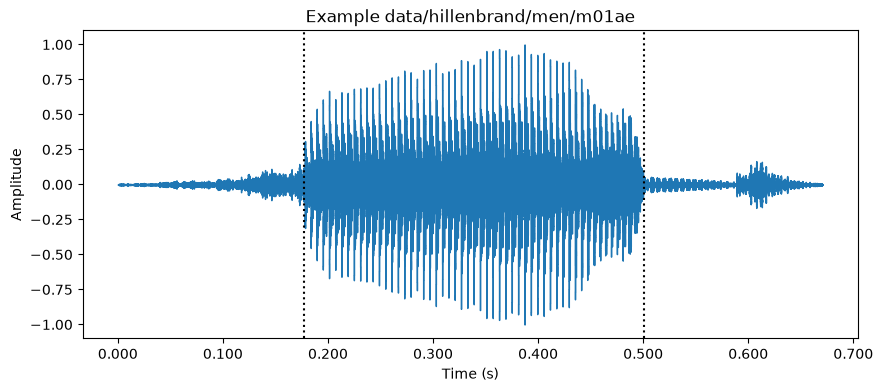

In [50]:
# Create the plot
fig, ax = plt.subplots(figsize=(10, 4))
lb.display.waveshow(audio, sr=sr, ax=ax)

# Add labels and show
ax.set(title=f'Example {example}', xlabel="Time (s)", ylabel="Amplitude")
plt.axvline(x=df_timedata['start'].iloc[0] / 1000, color='black', linestyle='dotted')
plt.axvline(x=df_timedata['end'].iloc[0] / 1000, color='black', linestyle='dotted')
plt.show()

The picture is not the sound, of course. To make the picture, we measure how much the air moves around a sensor at each point in time; record those distances; and end up with a list of numbers representing how much the air moved. We have to make a lot of measurements—usually 44,100 per second—but really, you can make as many or as few as you'd like. You just lose more information the less you listen.

That's what's actually inside of our `audio` object: Just numbers.

In [51]:
audio

array([ 0.00048828,  0.00048828,  0.00097656, ...,  0.00048828,
       -0.00097656,  0.        ], shape=(10730,), dtype=float32)

We make the following decisions:

- Each sound will last for **3 seconds**.
- We'll start by making every formant equally loud, with amplitudes of `0.2` (arbitrary).
- We'll assume 44,100 recordings, or **samples**, per second; number of samples per second is called the **sampling rate**.

In [12]:
# 1. constants
duration = 3.0
amplitude = 0.2
sample_rate = 44100

Why 44,100 Hz?

I said we use these lists of numbers to tell a speaker how to recreate it. Briefly:

- We read a number from the list.
- The number is converted to an electrical impulse of variable power.
- The impulse causes a speaker to move by a distance proportionate to the number in the list.

In other words: we literally use the number in the list, which measured how much the air moved, to tell a speaker, physically, how much to move the air.

The air is always moving. That never stops. Our recordings, however, only happen sometimes. When we look at the list later, we don't know what happened in between each recording.

In other words: The movement of the air is an **analog signal**; it's physical and continuous. Our list of numbers is **digital**; it's a discrete list of numbers we're using to represent the real, moving air.

Since analog signals are continuous and discrete representations are not, our list of numbers always loses some information. No way around it.

You can probably guess that taking more samples means more information: If I record every jillionth of a second, I'll have a lot more information than if I record every half. But that might be overkill—maybe you could take fewer samples, waste less space, and get the same quality when you play the audio back later. Or, maybe it's not—maybe a jillion recordings a second isn't enough.

How can you tell?

The easiest way to think about this is like framerate; we'll come back to sounds. 

For now, think of cameras. When you film a scene, you can opt for high-speed, like 120fps, which gives you lots of frames. Or, you can opt for 15fps, which saves space, but gets blurry if things speed up.

This is analogous. When we record a song, we can take a lot of recordings, which is great if the sound changes a lot: You need more samples to capture patterns that change a lot. If it doesn't, fewer samples is enough. In other words: The song is playing constantly. But your samples happen sometimes. And you lose information about whatever happens between them. So: More samples, more information. 

It's even deeper than this: Pitches sound different because they have different frequencies. Frequency is how many times a wave oscillates per second (unit time, but...). If a wave has high frequency, it oscillates very fast. If you sample too slowly, you can't detect it, because it's moving faster than you can sense it.

This might be confusing, because sound is unintuitive...But use the visual analogy, again. In the same way a bullet is hard to see for a normal camera—filming a muzzle capture the flash, not the lead—very high-frequency sounds are hard for a microphone to hear.

As it turns out, just like you can figure out how many frames per second a camera needs to capture to "see" a bullet, you can figure out how many samples you need per second for a recording device to "hear" a given frequency.

To figure it out, we'll have to think about what the air looks like when our microphone records it.

Remember what we said: The air is always moving—our snapshots only happen sometimes.

In the picture below, the smooth curve is the air: It's always moving. The dots are our recordings: They only happen sometimes.

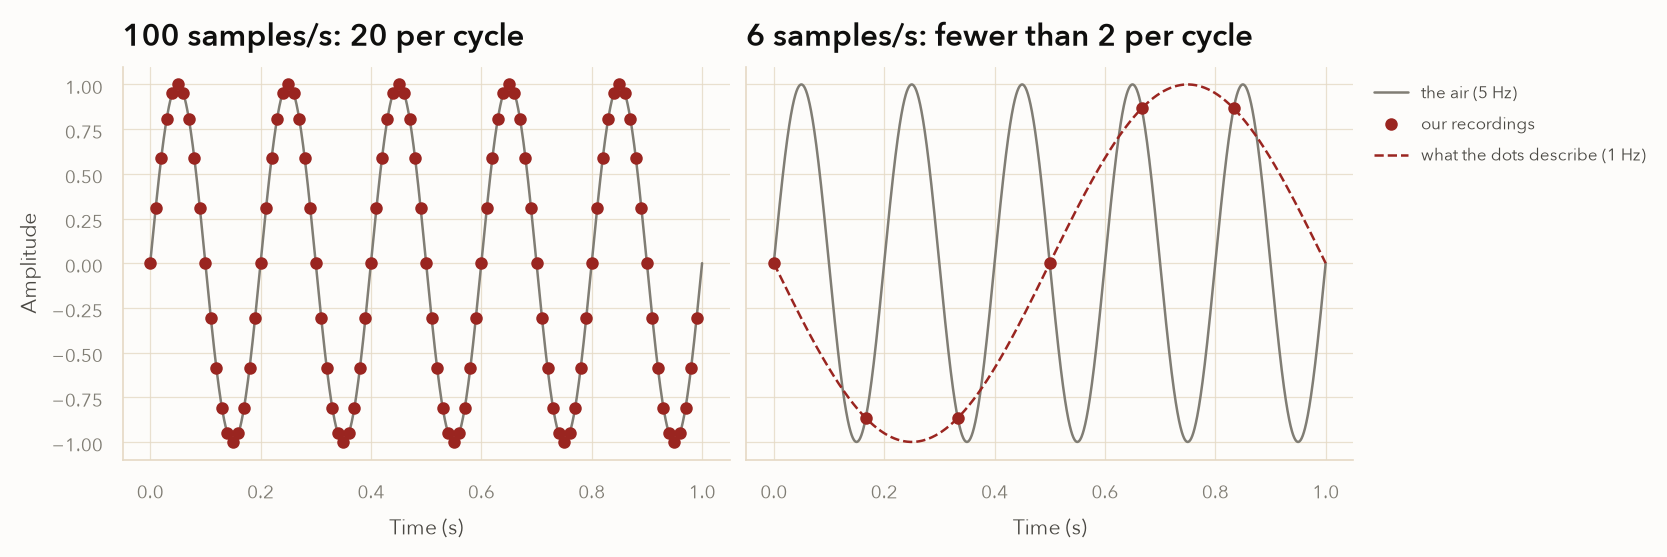

In [4]:
#| code-fold: true
# AI-generated figure (disclosed in _notes/edit-index-2026-11-09.md)
f = 5.0                                    # the "air": a 5 Hz wave
t = np.linspace(0, 1, 2000)                # dense grid stands in for continuous time
fig, (ax_l, ax_r) = plt.subplots(1, 2, figsize=(11, 3.6), sharey=True)

for ax, fs, title in [(ax_l, 100, "100 samples/s: 20 per cycle"),
                      (ax_r, 6, "6 samples/s: fewer than 2 per cycle")]:
    ts = np.arange(0, 1, 1 / fs)
    ax.plot(t, np.sin(2 * np.pi * f * t), color=PALETTE["muted"], lw=1.2, label="the air (5 Hz)")
    ax.plot(ts, np.sin(2 * np.pi * f * ts), "o", color=PALETTE["accent"], ms=5, label="our recordings")
    ax.set(title=title, xlabel="Time (s)")

# the slower wave that fits the right-hand dots exactly: 5 Hz sampled at 6 Hz reads as 5 - 6 = -1 Hz
ax_r.plot(t, np.sin(2 * np.pi * (f - 6) * t), "--", color=PALETTE["accent"], lw=1.2,
          label="what the dots describe (1 Hz)")
ax_l.set_ylabel("Amplitude")
ax_r.legend(loc="upper left", bbox_to_anchor=(1.01, 1.0), fontsize=8)
plt.show()

On the left, we have a lot of dots per cycle. On the right, we don't have enough.

The lists of numbers don't reveal anything special: We can still recreate something. But, listen...

In [5]:
# AI-generated demo (disclosed in _notes/edit-index-2026-11-09.md)
f_tone = 6000                      # a 6 kHz tone
d = 2.0                            # seconds

fs_good = 44100                    # plenty of samples per cycle
x_good = 0.3 * np.sin(2 * np.pi * f_tone * np.arange(0, d, 1 / fs_good))

fs_bad = 8000                      # not enough: fewer than 2 samples per cycle
x_bad = 0.3 * np.sin(2 * np.pi * f_tone * np.arange(0, d, 1 / fs_bad))

print(f"{f_tone} Hz recorded at {fs_good} samples/s")
ipd.display(ipd.Audio(x_good, rate=fs_good, normalize=False))
print(f"{f_tone} Hz recorded at {fs_bad} samples/s")
ipd.display(ipd.Audio(x_bad, rate=fs_bad, normalize=False))

6000 Hz recorded at 44100 samples/s
6000 Hz recorded at 8000 samples/s


Not the same thing. 

What happened is this: Our "camera" couldn't see fast enough. It caught some of the wave, at various points in time. But because it's moving so fast, what happens in between the snapshots actually matters.

When we use the data we do have to recreate the original sound, we end up with an incorrect, lower pitch, because our "camera" only saw some of the original, high-frequency wave, and mistook it for a slower one.

In [26]:
#| code-fold: true
# AI-generated interactive figure (disclosed in _notes/edit-index-2026-11-09.md).
# Plotly with precomputed slider frames, so it works in the static HTML book.
import plotly.graph_objects as go

f = 5.0                                     # true frequency of the "air"
t = np.linspace(0, 1, 1000)
air = np.sin(2 * np.pi * f * t)

def reconstruct(fs):
    """Whittaker-Shannon (sinc) interpolation: the band-limited curve through the samples."""
    n = np.arange(np.floor(-3 * fs), np.ceil(4 * fs) + 1)    # pad past [0, 1] to tame edge effects
    tn = n / fs
    xn = np.sin(2 * np.pi * f * tn)
    return np.sinc(fs * (t[:, None] - tn[None, :])) @ xn, tn, xn

def heard(fs):
    """Frequency the samples describe: f folded into [0, fs/2]."""
    return abs(f - fs * np.round(f / fs))

rates = np.round(np.arange(4.0, 30.01, 0.5), 1)
traces, steps = [], []
for k, fs in enumerate(rates):
    rec, tn, xn = reconstruct(fs)
    keep = (tn >= 0) & (tn <= 1)
    visible = k == len(rates) - 1
    traces += [
        go.Scatter(x=t, y=rec, mode="lines", line=dict(color=PALETTE["accent"], dash="dash"),
                   name="rebuilt from the dots", visible=visible),
        go.Scatter(x=tn[keep], y=xn[keep], mode="markers", marker=dict(color=PALETTE["accent"], size=8),
                   name="our recordings", visible=visible),
    ]
    vis = [True] + [False] * (2 * len(rates))
    vis[1 + 2 * k] = vis[2 + 2 * k] = True
    ok = "enough" if fs > 2 * f else "NOT enough"
    steps.append(dict(method="update", label=f"{fs:g}",
                      args=[{"visible": vis},
                            {"title": f"{fs:g} samples/s ({ok} for 5 Hz): the dots describe {heard(fs):.1f} Hz"}]))

fig = go.Figure([go.Scatter(x=t, y=air, mode="lines", line=dict(color=PALETTE["muted"]),
                            name="the air (5 Hz)")] + traces)
fig.update_layout(
    title=steps[-1]["args"][1]["title"],
    sliders=[dict(active=len(rates) - 1, currentvalue=dict(prefix="samples per second: "),
                  pad=dict(t=40), steps=steps)],
    xaxis_title="Time (s)", yaxis_title="Amplitude", yaxis_range=[-1.6, 1.6],
    template="simple_white", paper_bgcolor=PALETTE["background"], plot_bgcolor=PALETTE["background"],
    height=480, legend=dict(orientation="h", y=1.08, x=0),
)
# plain HTML output: plotly.js from CDN, and no MathJax (the book already loads its own)
ipd.display(ipd.HTML(fig.to_html(include_plotlyjs="cdn", include_mathjax=False, full_html=False)))

**Nyquist–Shannon sampling theorem.** If a signal contains no frequencies at or above $f_s/2$, it can be reconstructed exactly from samples taken $f_s$ times per second. Half the sampling rate, $f_s/2$, is called the **Nyquist frequency**. For the precise statement and its proof, see Julius O. Smith, [*Mathematics of the DFT*, "Sampling Theorem"](https://ccrma.stanford.edu/~jos/mdft/Sampling_Theorem.html).

Human hearing tops out around 20,000 Hz, so audio needs more than 40,000 samples per second. 44,100 clears that, which covers everything we hear, including all of our formant values.

Anyway. That's how we get our sample rate.

Now that we know we'll have 44,100 recordings per second to feed to our speaker, we need to make a list with three second's worth of recordings: That's `44,100 * 3 = 132,300` slots. It's just a list of zeros—it sounds like silence.

In [57]:
time_ = np.linspace(0, duration, int(duration * sample_rate), endpoint=False)

Now, we'll use our formant frequencies to make sound waves.

We need to make a wave-like picture, like those shown above, whose peaks match the frequencies in the table below. Turns out, we do that with trigonometry (...or complex exponentials, soon enough). 

In [58]:
df.iloc[0][['f0_ss', 'f1_ss', 'f2_ss', 'f3_ss', 'f4_ss']]

f0_ss       174
f1_ss       663
f2_ss    2012.0
f3_ss    2659.0
f4_ss    3691.0
Name: 0, dtype: object

In [59]:
# get what we need
row = df.iloc[0]
formant_frequencies = [row['f0_ss'], row['f1_ss'], row['f2_ss'], row['f3_ss'], row['f4_ss']]
formant_names = ['f0', 'f1', 'f2', 'f3', 'f4']

In [60]:
# light magic
formant_waveforms = {
   name: 20 * np.cos(2 * np.pi * freq * time_)
    for name, freq in zip(formant_names, formant_frequencies)
}

In [61]:
formant_waveforms

{'f0': array([20.        , 19.99385448, 19.97542169, ..., 19.94471296,
        19.97542169, 19.99385448], shape=(132300,)),
 'f1': array([20.        , 19.91083659, 19.64414138, ..., 19.20229231,
        19.64414138, 19.91083659], shape=(132300,)),
 'f2': array([20.        , 19.18386413, 16.80206429, ..., 13.04898771,
        16.80206429, 19.18386413], shape=(132300,)),
 'f3': array([20.        , 18.58186112, 14.52855629, ...,  8.4149004 ,
        14.52855629, 18.58186112], shape=(132300,)),
 'f4': array([20.        , 17.29766695,  9.92092821, ..., -0.13677576,
         9.92092821, 17.29766695], shape=(132300,))}

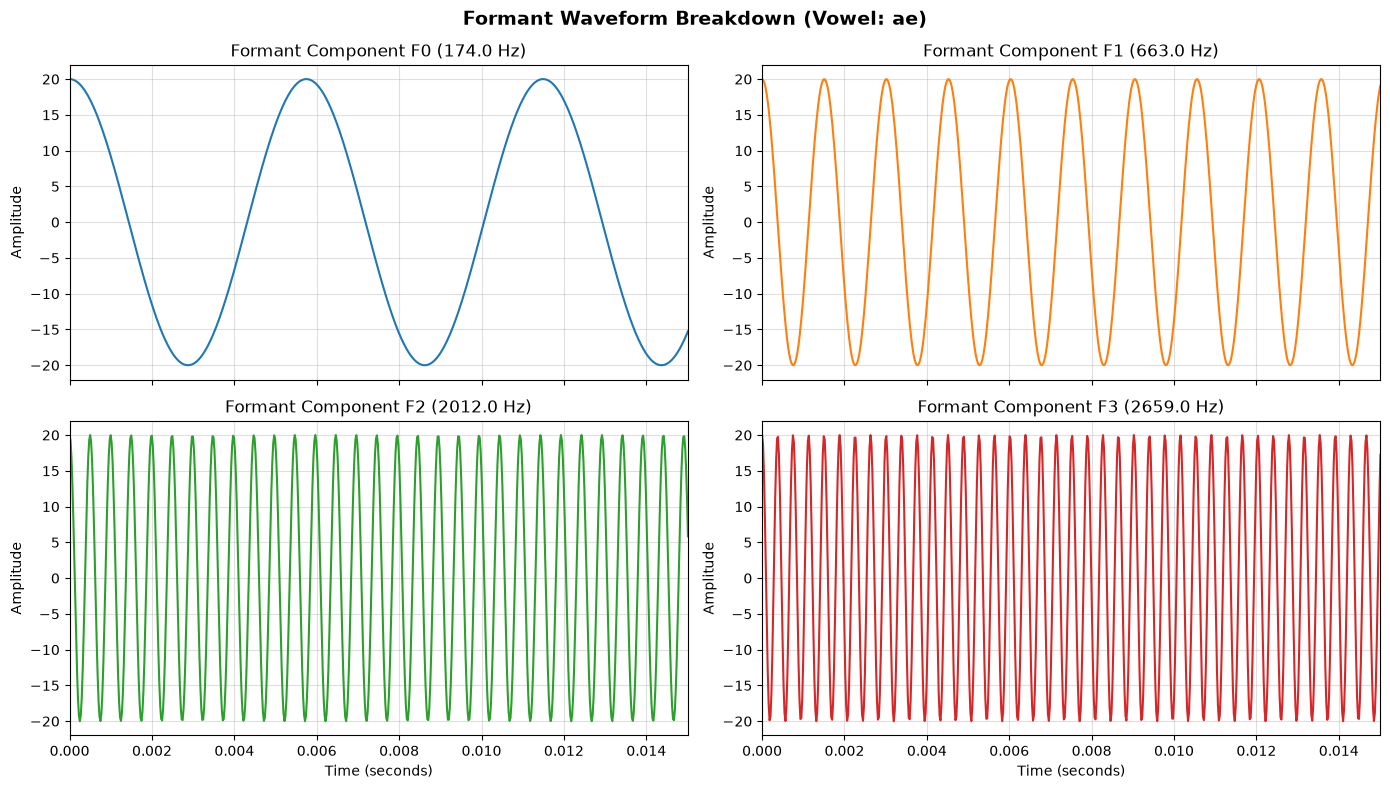

In [62]:
# --- 4-Up Visualization Block ---
fig, axs = plt.subplots(2, 2, figsize=(14, 8), sharex=True)
fig.suptitle(f"Formant Waveform Breakdown (Vowel: {row.get('vowel', 'Unknown')})", fontsize=14, fontweight='bold')

# Plotting the first 4 formants (f0, f1, f2, f3)
axes_flat = axs.flatten()
for i in range(4):
    name = f'f{i}'
    freq = formant_frequencies[i]
    ax = axes_flat[i]
    
    # Zoom in heavily on the time axis to see individual cycles clearly
    ax.plot(time_, formant_waveforms[name], color=f'C{i}', linewidth=1.5)
    ax.set_title(f"Formant Component {name.upper()} ({freq:.1f} Hz)")
    ax.set_ylabel("Amplitude")
    ax.grid(True, alpha=0.4)
    ax.set_xlim(0, 0.015)  # Display first 15 milliseconds

# Set shared X label at the bottom
for ax in axs[1, :]:
    ax.set_xlabel("Time (seconds)")

plt.tight_layout()
plt.show()

That looks right. Now, let's listen to one.

In [63]:
audio_data = np.int16(formant_waveforms['f1'] * 32767)
display(ipd.Audio(audio_data, rate=sample_rate))

That...Is technically a sound at a frequency, but it doesn't inspire confidence.

Let's combine them.

In [64]:
synthesized_vowel = sum(formant_waveforms.values())

In [65]:
# normalize by loudest sound to fix clipping...
synthesized_vowel /= np.max(np.abs(synthesized_vowel))

In [66]:
audio_data = np.int16(synthesized_vowel * 32767)
display(ipd.Audio(audio_data, rate=sample_rate))

That's an improvement—it sounds richer, and "round"-ish, somewhat like an "a"—but, compare it to our example...

In [67]:
example = df['path'].iloc[0]
audio, sr = lb.load(f'{example}.wav', sr=None)
ipd.Audio(audio, rate=sr)

Ours

- Sounds robotic;
- Doesn't immediately sound like an "a".

If we do the same thing with different formant values, we notice they do have an effect. Here's another half-baked synthesis, this time of an "i" vowel.

In [68]:
# grab i vowel
row = df.iloc[834]
formant_frequencies_ih = [row['f0_ss'], row['f1_ss'], row['f2_ss'], row['f3_ss'], row['f4_ss']]
formant_names_ih = ['f0', 'f1', 'f2', 'f3', 'f4']

# light magic
formant_waveforms_ih = {
   name: 20 * np.sin(2 * np.pi * freq * time_)
    for name, freq in zip(formant_names_ih, formant_frequencies_ih)
}

In [69]:
synthesized_vowel_ih = sum(formant_waveforms_ih.values())

In [70]:
# normalize by loudest sound to fix clipping...
synthesized_vowel_ih /= np.max(np.abs(synthesized_vowel_ih))

In [71]:
audio_data = np.int16(synthesized_vowel_ih * 32767)
display(ipd.Audio(audio_data, rate=sample_rate))

In [72]:
example = df['path'].iloc[834]
audio, sr = lb.load(f'{example}.wav', sr=None)
ipd.Audio(audio, rate=sr)

Still robotic. But the intended "vowel" is clearly different; it does subtly sound more like "ih" than "ah" to my ear.

So formant frequencies are clearly related to vowels...Something went right.

But something else clearly went wrong.

## Bandpass Synthesis

Small correction.

It's not that only F1-3 matter. It's that only F1-3 matter for distinguishing vowels: We need the other formants and resonances for a vowel to sound human.

Turns out, this is more like how voices work, anyway: The larynx produces a sound that, on its own, sounds like a buzz; that moving air gets "shaped" in your mouth to produce the sounds we know and love (and understand).

The shape of your mouth selects which resonances we hear; this, in turn, determines which vowel we perceive. When I say "a" and you say "a", we generate similar formant frequencies, but our voices are still different.

The first few formants determine the vowel; the rest determine the sound of you.

It's similar to the way a guitar sounds different from a violen. The same note played on a guitar sounds different on a violin. The reason is because, while the note is the same, what we hear is not the pure note: It's the result of the note ringing through the body of the instrument. The string makes a sound when plucked; the sound bounces around the guitar or violin body; and what we hear is what bounces back out. Just like with the mouth, the shape of the instrument determines the resonances, and therefore, the quality, or **timbre**, of the instrument.

Your voice is exactly the same: Your larynx generates a pulse train. Your mouth filters resonant frequencies, amplifying some frequencies and suppressing others. We only need a few formants to tell what you're saying—but we need all of them for it to sound like you.

Unfortunately, we've only got the four in our data set, and we can't exactly invent more at random.

The problem is that mixing four pure formants frequencies together is too "thin"; it leaves out all the infinity of other formants we need for it to sound like a voice. We can't make up infinity formants ourselves. Instead, we could start with a sound that has an infinite number of frequencies in it...And then filter out everything except for what's around our formant values.

It won't be perfect—we'll be losing any richness around other formants we don't have—but we'll get infinitely more richness than we currently have. So it's worth a shot.

The downside is: This complicates things a bit. We need to:

- Start with a "rich enough" sound
- Find a way to remove some frequencies—...but not all
- Compute new vowels

When I write it like that, it doesn't seem so bad. Let's try it out.

To start, we need a sound to filter out. We'll start by generating some noise.

In [87]:
sample_rate = 44100
duration = 2.0
frequency = df.iloc[0]['f0_ss']
amplitude = 10

In [88]:
time_ = np.linspace(0, duration, int(duration * sample_rate), endpoint=False)

In [89]:
# uncorrelated uniform noise
noise = np.random.uniform(-amplitude, amplitude, len(time_))

There's [a lot to say about noise](https://allendowney.github.io/ThinkDSP2/chap04.html); turns out, there are different kinds. We're using the absolute simplest: A list of purely random numbers.

In [90]:
audio_data = np.int16(noise * 32767)
display(ipd.Audio(noise, rate=sample_rate))

Sounds like it looks.

One of the reasons our synthesized vowel sounded too robotic was because it contained only four frequencies. In a real human voice, those are enough to distinguish vowels—but only if the others are there to give the voice its proper timbre.

Random noise—because it's random—contains lots of frequencies. This means, even if we filter out most of them, we'll still have a lot of random frequencies "near" the formants. This will make the vowel sound "richer", if not exactly like a voice.

Next, we need a way to remove frequencies from a sound. For this, you use a **filter**.

Our goal is to take noise, which as a little of every frequency, and remove almost everything, except for

- Our formant frequencies, which will determine the vowel
- Frequencies nearby, which will add "texture" to the synthesizer, and make it sound fuller

We know which formant frequencies to use; those come from the dataset. We have a couple of decisions to make:

- How close is "nearby"? 50 Hz? 5000?
- Should all formants be equally strong? Or should the filter for, e.g., F2, produce a weaker peak than the filter for F1?

The first number is the formant's **bandwidth**; the latter refers to its **gain**, or relative power. Both of these do matter; but since they're not included in our data, we'll set them based on known values...But we'll start with equal power.

A filter is a device that's able to take a sound, remove some frequencies, and pass the rest. Think of a speaker behind a door: You can't clearly hear higher frequencies, like voices or melodies, but you still feel the bass. In this case, the door is a **low pass filter**: It lets low-frequency bass tones through, but blocks the high ones.

In our case, we want to remove frequencies both lower and higher than a specific frequency, plus or minus the range we determine. This is called a **bandpass** filter. The specific frequency range we specify is called the **passband**—the range of frequencies that the filter allows through.

In our case, we need one filter for each formant; we'll end up with a list of three different filters. This list of filters is called a **filterbank**, which is a list of bandpass filters like ours.

The code below creates one filter for each formant, then applies them to the noise we started with, leaving us with just the frequencies around the formants.

More precisely: We use [scipy.signal.iirpeak](https://docs.scipy.org/doc/scipy/reference/generated/scipy.signal.iirpeak.html) to create three Butterworth filters, and then [scipy.signal.filtfilt](https://docs.scipy.org/doc/scipy/reference/generated/scipy.signal.filtfilt.html) to perform [zero-phase filtering](https://ccrma.stanford.edu/~jos/fp/Zero_Phase_Filters_Even_Impulse.html).

Our goal is to retain the formant frequencies and the sounds immediately around them, but nothing else. In other words, we want thin peaks at the formant frequencies, hence the use of [iirpeak](https://docs.scipy.org/doc/scipy/reference/generated/scipy.signal.iirpeak.html), which allows us to specify the frequency to be retained ($w_{0}$, the first argument), as well as the [Q factor](https://en.wikipedia.org/wiki/Q_factor), which describes the degree of damping. This, in turn, determines the "ringing"/sustain quality of the retained frequency.

If none of that made sense, don't worry—we actually don't need this again.

In [91]:
# grab formant frequencies again
formant_frequencies_ss = df.iloc[0][['f0_ss', 'f1_ss', 'f2_ss', 'f3_ss', 'f4_ss']].values
formant_frequencies_ss

array([np.int64(174), np.int64(663), np.float64(2012.0),
       np.float64(2659.0), np.float64(3691.0)], dtype=object)

In [92]:
# define bandwidths for F1-F3; they grow wider as frequency grows
bandwidths = [60.0, 70.0, 130.0]

In [93]:
def vowel_filter(carrier, formant_frequencies, bandwidths):
    # accumulator for synthesized vowel
    synthesized_vowel = np.zeros_like(carrier)
    # apply filters to noise
    for freq, bw in zip(formant_frequencies, bandwidths):
        Q = freq / bw
        # get transfer function coefficients
        b, a = scipy.signal.iirpeak(freq, Q, fs=sample_rate)
        # convert to SOS sections
        sos = scipy.signal.tf2sos(b, a)
        # add result to accumulator
        synthesized_vowel += scipy.signal.sosfiltfilt(sos, carrier)
    return synthesized_vowel

In [94]:
synthesized_vowel = vowel_filter(noise, formant_frequencies_ss[1:4], bandwidths)  # F1-F3 (index 0 is f0)

In [95]:
def play_vowel(synthesized_vowel):
    # normalize to prevent clipping
    synthesized_vowel /= np.max(np.abs(synthesized_vowel))

    audio_data = np.int16(synthesized_vowel * 32767)
    display(ipd.Audio(audio_data, rate=sample_rate))

In [96]:
play_vowel(synthesized_vowel)

In [97]:
example = df['path'].iloc[0]
audio, sr = lb.load(f'{example}.wav', sr=None)
ipd.Audio(audio, rate=sr)

This...Doesn't immediately sound better. Let's try an "ih" vowel.

In [98]:
# grab formant frequencies again
formant_frequencies_ss_ih = df.iloc[834][['f0_ss', 'f1_ss', 'f2_ss', 'f3_ss', 'f4_ss']].values
formant_frequencies_ss_ih

array([np.int64(179), np.int64(370), np.float64(2161.0),
       np.float64(2757.0), np.float64(3609.0)], dtype=object)

In [99]:
ih = vowel_filter(noise, formant_frequencies_ss_ih[1:4], bandwidths)

In [100]:
play_vowel(ih)

In [101]:
example = df['path'].iloc[834]
audio, sr = lb.load(f'{example}.wav', sr=None)
ipd.Audio(audio, rate=sr)

Not very human, but definitely distinguishable. One more...

In [102]:
f_freqs_ss_uh = df.iloc[1390][['f0_ss', 'f1_ss', 'f2_ss', 'f3_ss', 'f4_ss']].values
f_freqs_ss_uh

array([np.int64(171), np.int64(670), np.float64(1178.0),
       np.float64(2566.0), np.float64(3641.0)], dtype=object)

In [103]:
uh = vowel_filter(noise, f_freqs_ss_uh[1:4], bandwidths)

In [104]:
play_vowel(uh)

In [105]:
example = df['path'].iloc[1390]
audio, sr = lb.load(f'{example}.wav', sr=None)
ipd.Audio(audio, rate=sr)

...All right. We're not building synthesizers with it, but—it's clear that formant frequencies absolutely have something to do with perceived vowel quality.

The results aren't great, but consider: This is the simplest possible way to approach the problem, and these three "vowels" are, at least, distinguishable. By ear, it makes intuitive sense that an ML model should be able to use formant frequency as a classifier feature. 

We could make things more complicated and improve results with:

- A different carrier signal; it would be more correct to use an impulse train, for example.
- Dynamics; we're using steady state values only, so all dynamic character in speech is lost. These dynamics are important—hence the Hillenbrand data's inclusion of 20/50/80 values in addition to steady-state—and we're leaving them out entirely.
- Better thought-out bandwidths; these are fairly arbitrary.

We've learned:

- Constructing a "vowel" with sinusoids at formant frequencies doesn't work.
- Filtering out sounds except for formant frequences, with some noise...Kind of starts to work. The background noise is called the **source**, and the filters that strip away everything except the formant frequencies are called the, well, collective **filter**, yielding a **source-filter** model for vowels.
- Naive synthesis with bandpass filters isn't enough to get a convincing human sound; we're (apparently) missing overtones, dynamics, and lots of other stuff.
- It's clear formant frequencies, even naively applied, lead to distinguishable differences between synthesized vowels. It should be enough for an ML model to differenitiate between categories. 

## Inverting Construction

We've convinced ourselves that vowels do, indeed, have to do with formant frequencies; and have seen that the first three (in our case, four) are sufficient to distinguish vowels, even if it's not enough to synthesize a recognizably human sound.

That should convince us that formant frequencies are, in fact, useful for predicting vowels. That brings us back to the original question we had: What if Hillenbrand and friends hadn't handed us a table of formant values? Or, what if we need to compute it ourselves from samples like those in the WAV data?

Plots of amplitude over time are of no use; we'd want to be able to plot the frequencies in the sound, and how much influence each one makes to it.

We created our vowel sounds in two ways:

- **Direct Synthesis**: Tahe the formant frequencies. Attach them to cosines. Slap them together. Not very good; simple.
- **Source Filtering**: Apply a bandpass filterbank to a noise bed. Better; more complicated.

At a glance, inverting the source-filter model seems...Hard. The direct synthesis approach produced a rather poor "vowel" sound, but:

- It's simple: It's basically a bunch of multiplication and addition, and even I know how to turn those around.
- The results were, technically, distinguishable. Maybe it kind of works, but our ears don't detect it well; and reversing it might kind of work, and give us a good starting point.

Here's what we'll do:

- Revisit the original "construction from frequencies" approach we took earlier.
- Re-express it using matrices.
- Manipulate the expression to derive an equation for the frequencies
- Use linear algebra to solve it

...Then, we'll see how well the solution works on both our cruddy vowel (it should perfectly identify the four sinusoids we combined), and our fancier source-filtered ones (it should find power mostly, but not exclusively, around formant frequencies).

We started by observing the following:

- The dataset gives us formant frequencies. Sound waves are generated by air moving at a given frequency. Ergo, we can—maybe—synthesize a vowel by making sound waves at the appropriate frequencies.
- Sine waves can represent sound at a specific frequency. Stacking the right combination of sine waves can (maybe) give us a vowel sound.
- All we need is a list of included frequencies to create the new sound; that's enough to create a set of sine waves to synthesize.

We learned this doesn't really work for vowels, but it does let us create genuinely complex waves that approximate piano or guitar chords, but without the richness of resonance through the instrument body.

Let's rewrite our code, expressing it mathematically along the way.

We started with formant frequencies—specifically, steady-state values. These were:

In [92]:
for name, freq in zip(formant_names, formant_frequencies):
    print(f'{name}: {freq} Hz')

f0: 174 Hz
f1: 663 Hz
f2: 2012.0 Hz
f3: 2659.0 Hz
f4: 3691.0 Hz


To say this in general: Call each frequency an  $f_{i}$, with $i \in \{0, 1, 2, ...\}$. The frequencies above are real, but in general, we can have $f \in \mathbb{C}$.

We then used each frequency to generate cosine waves, like below:

In [93]:
name = 'f1'
freq = formant_frequencies[1]

duration = 1
sample_rate = 44100

In [94]:
# first, generate a timeline and compute cosine wave
timeline_ = np.linspace(0, duration, int(duration * sample_rate), endpoint=False)
cosine_wave_ = np.cos(2 * np.pi * freq * timeline_)

(0.0, 0.015)

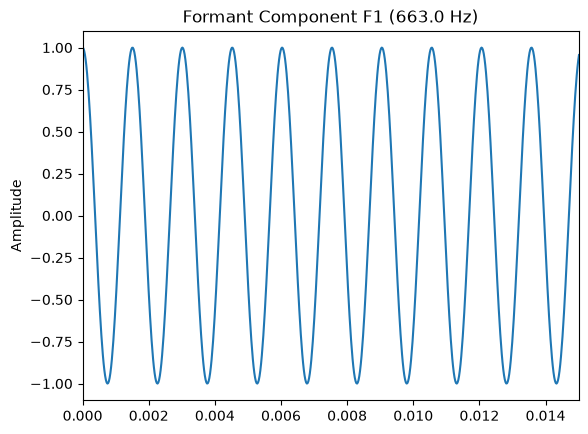

In [95]:
# one of the formant waves
plt.plot(timeline_, cosine_wave_)
plt.title(f"Formant Component {name.upper()} ({freq:.1f} Hz)")
plt.ylabel("Amplitude")
plt.xlim(0, 0.015)  # Display first 15 milliseconds

Mathematically, each equation has the form:

$$
g(f_{i}, a_{i}, t) = a_{i} \cos(2\pi f_{i} t + \phi) + C
$$

We only specified a frequency for each wave, and a uniform amplitude. In general, however, each $f_{i}$ is associated with 

- An **amplitude**, $a_{i} \in \mathbb{C}, \space i \in \{0, 1, 2, ...\}$;
- A **phase**, $\phi_{i}, \phi \in [0, 2\pi]$;
- A **DC offset**, $C \in \mathbb{R}$.
  - ...But we'll ignore this. Offsets contribute a constant amount of extra power; constants don't change, so in the frequency spectrum, it appears as 0 Hz signal; this leads to an additional spike 0 Hz in the DFT, but nowhere else; for our purposes, we're typically interested in the _alternating current_, or **AC**, since we're explicitly concerned with frequencies. 

Alternatively, can say we did include phase and offset earlier, but set them to zero.

At this point, we might recall Euler's formula:

$$
A e^{i \omega t + \phi} = A(\cos(\omega t + \phi) + i \sin(\omega t + \phi)) 
$$


Observe that our cosine function is just $\operatorname{Re}(A_{i} e^{2\pi i f_{i} t})$.

Because the imaginary part of the complex exponential doesn't influence the real signal, this means we can use the complex exponential instead of cosine without altering our results from earlier; and because linear algebra is valid over arbitrary fields, we don't need to adjust our matrix algorithm, either.

Next, we combined each of our cosine functions by taking a simple sum. In code, that looked like:

In [96]:
synthesized_vowel_ih = sum(formant_waveforms_ih.values())

Simple. In math, using cosine:

$$
S_{out} = \sum_{i}^{N} a_{i} \cos(2\pi f_{i} t + \phi)
$$

...Less simple looking, but the same thing: Take the values of each function evaluated over $t$; sum them; return.

Using complex exponentials:

$$
S_{out} = \sum_{i}^{N} A_{i} e^{2\pi f_{i} t + \phi_{i}} + C_{i}
$$

...Where $S_{out}$ is the output signal.

Either way, we're simply taking a linear combination of the form:

$$
S_{out} = \sum_{i}^{N} A_{i} \mathbf{e}_{i}
$$

...Where $A_{i}$ are the amplitudes in frequency space, and $\mathbf{e}_{i}$ represents the complex exponentials. Again, we ignore $C_{i}$ without loss of generality.

This doesn't buy us anything new; I'm just emphasizing that, despite the gnarly exponent, we're just adding vectors. 

One hiccup. The above equations assume $t \in \mathbb{R}$; i.e.:

- They treat time as continuous;
- Nothing about the above has to do with evaluation.

This raises two corresponding problems:

- We're working with a computer; everything is discrete.
- We need to actually compute these functions; we want to hear something, after all.

Fortunately, we already did this earlier, so there's nothing new; let's just describe it formally.

To represent our conceptual solution with matrices—or arrays, for that matter—we first need to discretize time.

Note that our complex exponentials are fully characterized by the 4-tuple $(f_{i}, A_{i}, \phi_{i}, C_{i})$, described above. Evaluation is essentially equivalent to sampling the continuous, "analog" signal defined by the underlying function by "measuring" it at select instants over the interval $t$; it's up to us to determine how to perform that sampling.

We're solving the synthesis problem, where we evaluate each sinusoid on a half-open interval $[0, d)$ of user-specified length. Thus, each complex exponential expands to an evaluated vector of length $k = f_{s} \cdot d$. In our case, we emulated a sampling rate of 44,100 Hz ($f_{s}$) over three seconds ($d$). 

These column vectors are then collected into a matrix $M$. Each column contains the values of one of our complex exponentials evaluated along the timeline.

Finally, we take the linear combination of the result, scaling each column vector by its amplitude. Conveniently, this is the definition of the matrix-vector dot product of $M$ with our amplitude vector, $\mathbf{a}$. 

This leads to the matrix representation below:

$$
M\mathbf{a} = S_{out}
$$

Thus:

$$
M\mathbf{a} = 
\begin{bmatrix}
e^{2\pi i f_{0} t_{0}} &  e^{2\pi i f_{1} t_{0}}  & \ldots & e^{2\pi i f_{2} t_{0}}\\
e^{2\pi i f_{0} t_{1}} &  e^{2\pi i f_{1} t_{1}}  & \ldots & e^{2\pi i f_{2} t_{1}}\\
e^{2\pi i f_{0} t_{2}} &  e^{2\pi i f_{1} t_{2}}  & \ldots & e^{2\pi i f_{2} t_{2}}\\
& \ldots
\end{bmatrix}
\begin{bmatrix}
A_{0} \\
A_{1} \\
A_{3} \\
\ldots
\end{bmatrix} =
A_{0}
\begin{bmatrix}
e^{2\pi i f_{0} t_{0}} \\
e^{2\pi i f_{0} t_{1}} \\
e^{2\pi i f_{0} t_{2}} \\
\ldots
\end{bmatrix} + \ldots 
A_{N}
\begin{bmatrix}
e^{2\pi i f_{N} t_{0}} \\
e^{2\pi i f_{N} t_{1}} \\
e^{2\pi i f_{N} t_{2}} \\
\ldots
\end{bmatrix} =
\sum_{i}^{N} A_{i} e^{2 \pi i f_{i} t_{j}} =
S_{out}
$$

...We don't have true equality with what I wrote above; keep in mind that the matrix representation discretizes the continuous function of $t$ we started with.

In any case, we see that the matrix equation on the left produces our signal on the right. Let's package the math up in some code, and use it.

In [14]:
class SimpleSynthesizer:

    def __init__(self, amplitudes, frequencies, duration: float = 1.0, sampling_rate: int = 44100):
        self.amplitudes = np.array(amplitudes)
        self.frequencies = frequencies
        self.duration = duration
        self.sample_rate = sample_rate
        self.evaluated = None

    def synthesize(self):
        if self.evaluated:
            return self.evaluated
        # produce M
        ts = np.linspace(0, self.duration, int(self.duration * self.sample_rate), endpoint=False)
        partial_args = np.outer(ts, self.frequencies)
        # compute exponentiated matrix
        M = np.exp(2 * np.pi * 1j * partial_args)
        # dot with amplitudes
        self.evaluated = np.dot(M, self.amplitudes)
        
        return self.evaluated

In [98]:
amps = np.array([0.6, 0.25, 0.1, 0.05, 0.1])
fs = [100, 200, 300, 400]
framerate = 11025
ts = np.linspace(0, 1, framerate, endpoint=False)

In [99]:
res_ = SimpleSynthesizer(
    # uniform amplitudes
    amplitudes=[10 for f in formant_frequencies],
    frequencies=formant_frequencies,
).synthesize()

In [100]:
# ignore warning; we have no imaginary data of meaning
play_vowel(res_)

/var/folders/zd/whvxk10d74148p1krxw0hq000000gn/T/ipykernel_80366/1867429590.py:5: ComplexWarning: Casting complex values to real discards the imaginary part
  audio_data = np.int16(synthesized_vowel * 32767)


Let's try a B♭ Major 6 chord:

- B♭ (Root): 233.08 Hz
- D (Major 3rd): 293.66 Hz
- F (Perfect 5th): 349.23 Hz
- G (Major 6th): 392.00 Hz

In [15]:
bm6_freqs = [233.08, 293.66, 349.23, 392.00]
bm6_amps = np.array([0.6, 0.25, 0.1, 0.05])
bm6 = SimpleSynthesizer(bm6_amps, bm6_freqs).synthesize()

play_vowel(bm6)

/var/folders/zd/whvxk10d74148p1krxw0hq000000gn/T/ipykernel_71754/1867429590.py:5: ComplexWarning: Casting complex values to real discards the imaginary part
  audio_data = np.int16(synthesized_vowel * 32767)


It works.

More importantly—this is all we need to go in the reverse direction.

If we're given $S_{out}$, which specifies $t$, we can solve for $a$ by selecting a set of $N$ frequencies we think will suffice to construct the signal and solving a **system of equations**. 

$$
\begin{aligned} 
y = Ma \implies  
\begin{bmatrix} 
y_0 \\
y_1 \\
y_2 \\
\vdots \\
y_{N-1} 
\end{bmatrix} = 
\begin{bmatrix} 
e^{2\pi i f_{0} t_{0}} & e^{2\pi i f_{1} t_{0}} & e^{2\pi i f_{2} t_{0}} & \dots & e^{2\pi i f_{N-1} t_{0}} \\
e^{2\pi i f_{0} t_{1}} & e^{2\pi i f_{1} t_{1}} & e^{2\pi i f_{2} t_{1}} & \dots & e^{2\pi i f_{N-1} t_{1}} \\
e^{2\pi i f_{0} t_{2}} & e^{2\pi i f_{1} t_{2}} & e^{2\pi i f_{2} t_{2}} & \dots & e^{2\pi i f_{N-1} t_{2}} \\
\vdots & \vdots & \vdots & \ddots & \vdots \\
e^{2\pi i f_{0} t_{N-1}} & e^{2\pi i f_{1} t_{N-1}} & e^{2\pi i f_{2} t_{N-1}} & \dots & e^{2\pi i f_{N-1} t_{N-1}} 
\end{bmatrix} 
\begin{bmatrix} 
A_{0} \\ 
A_{1} \\ 
A_{2} \\ 
\vdots \\ 
A_{N-1} 
\end{bmatrix} 
\end{aligned}
$$


Instead of multiplying forward, we use $M$, which contains data about our frequencies, to solve for $a$, their corresponding amplitudes.

...Can also be written as:

$$
\begin{cases} 
A_0 e^{2\pi i f_0 t_0} + A_1 e^{2\pi i f_1 t_0} + A_2 e^{2\pi i f_2 t_0} + \dots + A_{N-1} e^{2\pi i f_{N-1} t_0} = y_0 \\
A_0 e^{2\pi i f_0 t_1} + A_1 e^{2\pi i f_1 t_1} + A_2 e^{2\pi i f_2 t_1} + \dots + A_{N-1} e^{2\pi i f_{N-1} t_1} = y_1 \\
A_0 e^{2\pi i f_0 t_2} + A_1 e^{2\pi i f_1 t_2} + A_2 e^{2\pi i f_2 t_2} + \dots + A_{N-1} e^{2\pi i f_{N-1} t_2} = y_2 \\
\vdots \\
A_0 e^{2\pi i f_0 t_{N-1}} + A_1 e^{2\pi i f_1 t_{N-1}} + A_2 e^{2\pi i f_2 t_{N-1}} + \dots + A_{N-1} e^{2\pi i f_{N-1} t_{N-1}} = y_{N-1} 
\end{cases}
$$

...Or, more compactly:

$$
\sum_{k=0}^{N-1} A_k e^{2\pi i f_k t_n} = y_n \quad \text{for } n = 0, 1, \dots, N-1
$$

Looks ugly, but [numpy.linalg.solve](https://numpy.org/devdocs/reference/generated/numpy.linalg.solve.html) does this for us.

In [102]:
class SimpleAnalyzer:

    def __init__(self, signal, frequencies, times):
        self.frequences = frequencies
        self.times = times
        self.signal = signal

    def analyze(self):
        partial_args = np.outer(self.times, self.frequencies)
        M = np.exp(2 * 1j * np.pi * partial_args)
        a = np.linalg.solve(M, self.signal)
        return a

This technically works, but is cruddy to use. I have to pass frequencies and times...It would be better to just send the signal.

We'll make assumptions:

- Your sample is **one unit** of time long. We don't care what unit of time; we'll just say, however long your signal is, that's the unit of time, and we have one of them.
- Your sampling rate is **equal to the length of the sample**. I.e., your sampling rate was $N$.

If your sampling rate wasn't $N$, the DFT produces the same results—but the resolution of your interpretation will change. We'll come back to that.

Making these assumptions lets us rewrite things more succinctly.

In [103]:
class SimpleAnalyzer:

    def __init__(self, signal):
        self.signal = signal

    def analyze(self):
        N = len(self.signal)
        times = np.arange(N) / N
        frequencies = np.arange(N)
        
        partial_args = np.outer(times, frequencies)
        M = np.exp(2 * np.pi * 1j * partial_args)
        return np.linalg.solve(M, self.signal)

This is the answer were looking for: Turning a sound into a spectrum is possible.

And we already know how to do it.

...Kind of.

If you try to actually run this...It doesn't work. 

Or, it does—but you'll wonder what broke, because it'll take forever; it takes minutes to compute $M$. And that's not even the slow part. 

So, a solution exists. But this one is useless.

A couple other caveats:

- In the forward direction, the number of sinusoids $N$ bounds the possible complexity of our output. A single component is a pure sine wave; a handful is like a chord; a few hundred could start to sound like a guitar if you choose them correctly. Bigger $N$ = more complicated sound potential.
- In the reverse, $N$ corresponds to the number of frequencies in an input we can pick out. Remember: We're solving an equation that asks: _how much does each of these complex exponentials contribute to the input wave_?
  - If you hand me a signal that contains the frequencies 100 Hz, 150 Hz, and 200 Hz, but only use sinusoids at 100 Hz and 200 Hz, you completely miss the component at 150 Hz. If you try to recreate the original input, it won't work; you'll be missing a whole frequency component. In this way, $N$ determines resolution of the analysis algorithm: Higher $N$ means we can pick out more frequencies, with smaller differences between them.

Most real sounds need large $N$ to be faithfully reproduced. We also need to sample at 44,100 Hz to account for human hearing. This leads to large numbers pretty quickly; we couldn't even run this solution on our fake, one-second example. That was 44,100, the minimum, and already broke.

Solving the system of equations directly is $O(n^{3})$ time, in general; there's no way to speed this approach up. It's entirely useless.

That's a bummer, but the matrix equation reveals an alternative approach. If we could find the inverse of $M$, then we could write:

$$
\begin{aligned}
& S_{out} = M\mathbf{a} \\
& M^{-1}S_{out} = M^{-1}M\mathbf{a} \\
& M^{-1}S_{out} = I{a} = a
\end{aligned}
$$

If we have $M^{-1}$, solving the system of equations reduces to a simple matrix multiplication.

In this case, we just compute a dot product between each column of $M^{1}$ and $S_{out}$; that's work proportional $N$ operations per $N$ elements of $S_{out}$, for time complexity of $O(n^{2})$, since our matrix is square.

That's a huge improvement...But computing inverses is generally expensive—[at least](https://cstheory.stackexchange.com/questions/3921/what-is-the-actual-time-complexity-of-gaussian-elimination) $O(n^{3})$, often worse in practice.

Let's take a big step back and figure out what $M^{-1}$ does physically: then, we might be able to construct it directly.

We know $M^{-1}$ is the reverse of $M$; and $M$ contains the values of each constituent complex exponential. So, $Ma$ computes a weighted combination of signals with amplitudes.

That means, for  $M^{-1}S_{out}$ to somehow compute $a$, $M^{-1}$ must eat our signal; somehow test it against the same frequencies contained in $M$ (or else it couldn't reverse it); and then report a measurement of how much each one contributes to $S_{out}$. 

More directly: $M^{-1}$ must correlate each frequency in $M$ against $S_{out}$; and spit out a list measuring how much each it's correlated to each frequency.

You could build a machine that does this. Imagine a black box, containing a row of tuning forks, ranging from 1 Hz to...N Hz. It's a really big box. 

Each fork is perfectly sensitive—it resonates to a specific frequency, and only that frequency.

The tine of each fork is inside the box; some portion of the handle sticks out. When a fork resonates, the handle shakes. We can measure how much to determine how strongly a fork is vibrating.

Now: If we play a sound through the box, it will cause some forks to vibrate—but only those that respond to frequencies contained within the sound, in proportion to how strongly it contributes. 

Measuring how much each handle moves gives us a list of amplitudes associated with each frequency.

Assuming you have enough forks, you could decompose any sound this way. If, later, you ring each fork exactly the amount you recorded, you'll reproduce the input sound—the correlation are enough to perfectly reconstruct the analog signal from a digital representation.

Each tuning fork in the box responds to a single frequency: That means we can represent each tuning fork with a specific complex exponential.

Our complex exponentials and input signal are represented as vectors. We can determine the similarity between two vectors, like our machine measures the similarity between a sound and a tuning fork, by checking the angle between them: If two vectors overlap perfectly, they're the same (up to scale), and the angle between them is zero degrees, and they line up perfectly. If they don't overlap at all, they end up at ninety degree angles, or orthogonal, to one another.

The cosine of this angle is called **cosine similarity**, and measures...Well, similarity. It turns out cosine similarity is equivalent to **correlation** (...of mean-centered, variance-normalized vectors).

...But, since we're using complex numbers, we have to use an [inner product](https://en.wikipedia.org/wiki/Inner_product_space), instead; remember to take the complex conjugate of the second operand.

To check how much a single complex exponential overlaps our signal, we compute:

$$
A_k = \frac{1}{N}\langle S, \mathbf{e}_k \rangle
    = \frac{1}{N}\sum_{n=0}^{N-1} S[n]\,\overline{e^{2\pi i k n / N}}
    = \frac{1}{N}\sum_{n=0}^{N-1} S[n]\,e^{-2\pi i k n / N}
$$

To compute how much every complex exponential overlaps our signal, all at once, we build a matrix, and compute:

$$
\frac{1}{N}
\begin{bmatrix}
1 & 1 & 1 & \cdots & 1 \\
1 & e^{-2\pi i \cdot 1 \cdot 1/N} & e^{-2\pi i \cdot 1 \cdot 2/N} & \cdots & e^{-2\pi i \cdot 1 \cdot (N-1)/N} \\
1 & e^{-2\pi i \cdot 2 \cdot 1/N} & e^{-2\pi i \cdot 2 \cdot 2/N} & \cdots & e^{-2\pi i \cdot 2 \cdot (N-1)/N} \\
\vdots & \vdots & \vdots & \ddots & \vdots \\
1 & e^{-2\pi i (N-1) \cdot 1/N} & e^{-2\pi i (N-1) \cdot 2/N} & \cdots & e^{-2\pi i (N-1)(N-1)/N}
\end{bmatrix}
\begin{bmatrix}
S[0] \\ S[1] \\ S[2] \\ \vdots \\ S[N-1]
\end{bmatrix}
=
\begin{bmatrix}
A_0 \\ A_1 \\ A_2 \\ \vdots \\ A_{N-1}
\end{bmatrix}
$$

...But the right side of this is $a$; the vector on the left is $S_{out}$; so the matrix must be $M^{-1}$, the matrix that correlates each of our test frequencies with the input signal.

So it turns out we can build the inverse $M^{-1}$.

It gets better. To use the numbers $M^{-1}$ spits out and reconstruct the signal later, we need to scale each test frequency in $M^{-1}$ by the amplitudes it produced. So, we take every row in $M^{-1}$; take its dot product with $a$; and sum the result.

$$
S[n] = \sum_{k=0}^{N-1} A_k \, e^{2\pi i k n / N}
$$

In matrix form, that looks like this:

$$
\begin{bmatrix}
S[0] \\ S[1] \\ S[2] \\ \vdots \\ S[N-1]
\end{bmatrix}
=
\begin{bmatrix}
1 & 1 & 1 & \cdots & 1 \\
1 & e^{2\pi i \cdot 1 \cdot 1/N} & e^{2\pi i \cdot 1 \cdot 2/N} & \cdots & e^{2\pi i (N-1) \cdot 1/N} \\
1 & e^{2\pi i \cdot 2 \cdot 1/N} & e^{2\pi i \cdot 2 \cdot 2/N} & \cdots & e^{2\pi i (N-1) \cdot 2/N} \\
\vdots & \vdots & \vdots & \ddots & \vdots \\
1 & e^{2\pi i \cdot 1 \cdot (N-1)/N} & e^{2\pi i \cdot 2 \cdot (N-1)/N} & \cdots & e^{2\pi i (N-1)(N-1)/N}
\end{bmatrix}
\begin{bmatrix}
A_0 \\ A_1 \\ A_2 \\ \vdots \\ A_{N-1}
\end{bmatrix}
= M\mathbf{a}
$$

...But this is exactly the $M$ we started with: The rows of $M^{-1}$ correspond to the columns of $M$.

Look again: Conjugating each row of $M^{-1}$ and transposing it produces each of the columns of $M$, scaled by $\frac{1}{N}$. In other words, $M^{-1} = \frac{1}{N}M^{H}$, where $M^{H}$ is the conjugate transpose (more below).

All we have to do to invert $M$ is swap its entries, conjugate them, and divide by $N$. That means we can implement our quadratic algorithm right away.

A quick note on transposes. With a real matrix, you simply flip entries along the diagonal. If the matrix is complex, like $M$, we both transpose entries, and take the complex conjugate of each entry. The result of these two operations is called the **conjugate transpose**, but I prefer the quantum mechanical parlance of "[Hermitian adjoint](https://en.wikipedia.org/wiki/Hermitian_adjoint)".

Anyway, that last expression is curious: $M^{-1} = \frac{1}{N}M^{H}$. An inverse that is just a scaled conjugate transpose only happens when the columns of $M$ are orthogonal. Let's review what that means.

## Orthogonality Review

A real matrix is **orthogonal**, or **unitary** if complex, if all of its columns are perpendicular and each has length one. If you can show that, its (conjugate) transpose equals its own inverse.

If the columns are perpendicular but all have the same length $L$, the inverse is the (conjugate) transpose divided by $L^{2}$. That's our case: each column of $M$ has length $\sqrt{N}$, so $M^{-1} = \frac{1}{N}M^{H}$, and $\frac{1}{\sqrt{N}}M$ is unitary.

The simplest example of an orthogonal matrix is:

$$
\begin{bmatrix}
1 & 0 \\
0 & 1
\end{bmatrix}
$$

...Which represents a basis for the $xy$-plane. We can see that $\hat{\imath}$ and $\hat{\jmath}$ are perpendicular because...Well, we have eyes, but numerically, we confirm by testing that their dot product is zero.

In [104]:
i_hat = np.array([1, 0])
j_hat = np.array([0, 1])
np.dot(i_hat, j_hat)

np.int64(0)

We also know they each have length one because each only has one component, of length one.

We can verify with NumPy.

In [105]:
np.linalg.norm(i_hat)

np.float64(1.0)

In [106]:
np.linalg.norm(j_hat)

np.float64(1.0)

An orthogonal matrix whose vectors are all of length one is called **orthonormal**. Unitary matrices are automatically orthonormal.

In general, you check for length using the $L^{2}$ norm, or Euclidean distance, applied to the vector's components. If a vector $\mathbb{v}$ is a unit vector, then:

$$
1 = \lVert v_{i} \rVert
$$

...In our case:

$$
\begin{aligned}
& \hat{\imath} = (1, 0) \to \lVert \hat{\imath} \rVert = \sqrt{1^{2} + 0^{2}} = 1 \\
& \hat{\jmath} = (0, 1) \to \lVert \hat{\jmath} \rVert = \sqrt{0^{2} + 1^{2}} = 1
\end{aligned}
$$

Orthonormal matrices are nice; they preserve lengths and volumes under transformation due to their normality, and their inverse is equal to their transpose. That makes their transformations nicely reversible, and fast to compute.

Again: $M^{H}M = N I$, and so $M^{-1} = \frac{1}{N}M^{H}$, is true if and only if the columns of $M$ are orthogonal and each has squared length $N$. Since we know $M^{-1} = \frac{1}{N}M^{H}$, the columns of $M$ must be orthogonal, and so the complex exponentials comprising $M$ must be orthogonal.

...That's a bit unexpected: What does it mean for complex exponentials to be perpendicular?

Intuitively, it means that, when we decompose a signal with our tuning forks, we can be 100% sure that the measurement taken by a tuning fork is accurate: There's a 0% chance that some other fork is also ringing. There's no overlap in the sensitivity of each fork.

Each fork's measurement is completely independent of the others.

The fact that there's no overlap between complex exponentials is the clue: It suggests that, if two complex exponentials are orthogonal, their inner product is zero.

Consider the partial inner product, before we take the sum: If we multiply two sinusoids at different frequencies, we generate a perfectly symmetrical curve. 

This is what it looks like right before we actually take the dot product and add things up. Doing that equates to summing the areas under those curves—which is the continuous version of what we do when we take an inner product—and you can see that they cancel out.

If the frequencies overlap, the area is positive, because we end up squaring the signal; wherever the original is negative, the product is positive; and wherever it was positive, it's now bigger.

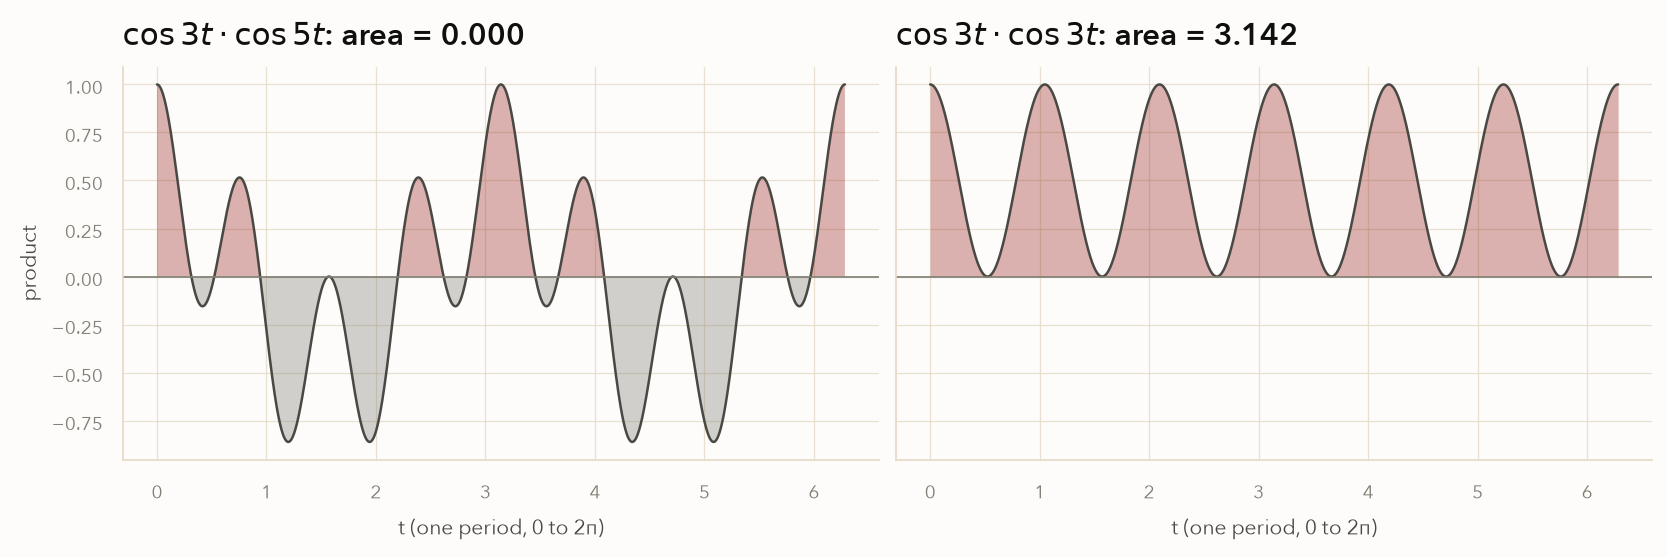

In [10]:
#| code-fold: true
# AI-generated figure (disclosed in _notes/edit-index-2026-11-09.md)
t = np.linspace(0, 2 * np.pi, 2000)
fig, (ax_l, ax_r) = plt.subplots(1, 2, figsize=(11, 3.6), sharey=True)

for ax, (m, n) in [(ax_l, (3, 5)), (ax_r, (3, 3))]:
    prod = np.cos(m * t) * np.cos(n * t)
    area = round(np.trapezoid(prod, t), 3) + 0.0   # + 0.0 turns -0.0 into 0.0
    ax.plot(t, prod, color=PALETTE["text"], lw=1.2)
    ax.fill_between(t, prod, 0, where=prod >= 0, color=PALETTE["accent"], alpha=0.35, lw=0)
    ax.fill_between(t, prod, 0, where=prod < 0, color=PALETTE["muted"], alpha=0.35, lw=0)
    ax.set(title=rf"$\cos {m}t \cdot \cos {n}t$: area = {area:.3f}", xlabel="t (one period, 0 to 2π)")
    ax.axhline(0, color=PALETTE["muted"], lw=0.8)

ax_l.set_ylabel("product")
plt.show()

If our case were continuous, a straightforward evaluation of the integrals over a period would prove this is the case.

In [11]:
# AI-generated check (disclosed in _notes/edit-index-2026-11-09.md)
import sympy as sp_
t_ = sp_.symbols("t", real=True)
m_, n_ = sp_.symbols("m n", integer=True, positive=True)

# continuous: the integral over one period, for two different and two equal frequencies
print("m != n:", sp_.simplify(sp_.integrate(sp_.cos(m_ * t_) * sp_.cos(n_ * t_), (t_, 0, 2 * sp_.pi)).subs({m_: 3, n_: 5})))
print("m == n:", sp_.integrate(sp_.cos(3 * t_) ** 2, (t_, 0, 2 * sp_.pi)))

# discrete (our case): the columns of M are orthogonal, each with squared length N
N_ = 64
n_idx = np.arange(N_)
M_ = np.exp(2j * np.pi * np.outer(n_idx, n_idx) / N_)
print("M^H M == N I:", np.allclose(M_.conj().T @ M_, N_ * np.eye(N_)))

m != n: 0
m == n: pi
M^H M == N I: True


The same idea proves the columns of our matrix are exactly orthogonal. The discrete version is a geometric series: for $k \neq l$, $\sum_{n=0}^{N-1} e^{2\pi i (k-l) n / N} = 0$, and for $k = l$ every term is 1, so the sum is $N$. The check above confirms it numerically for $N = 64$.

For the full proof, read Julius O. Smith's [*Mathematics of the DFT*, "Orthogonality of the DFT Sinusoids"](https://ccrma.stanford.edu/%7Ejos/mdft/Orthogonality_DFT_Sinusoids.html).

Because we know the columns of $M$ are orthogonal, we can use $M^{-1} = \frac{1}{N}M^{H}$ to compute the more efficient solution.

In [16]:
class SimpleAnalyzer:

    def __init__(self, signal):
        self.signal = signal

    def analyze(self):
        N = len(self.signal)
        times = np.arange(N) / N
        frequencies = np.arange(N)
        partial_args = np.outer(times, frequencies)
        M = np.exp(2 * np.pi * 1j * partial_args)
        # remember: M is complex, take conjugate transpose
        return M.conj().transpose().dot(self.signal) / N

This is technically better, but you wouldn't be able to tell. It's still too slow to run on our entire, measly, one-second dummy sound.

...But it does work if we run it on a tiny slice.

In [17]:
bm6_short = SimpleSynthesizer(bm6_amps, bm6_freqs, duration=0.1).synthesize()

In [18]:
amps = SimpleAnalyzer(bm6_short).analyze()
amps

array([0.00496394+0.00792141j, 0.00516999+0.00825535j,
       0.00539464+0.00861878j, ..., 0.00443672+0.00706426j,
       0.00459905+0.0073286j , 0.00477425+0.00761348j], shape=(4410,))

Lovely. Let's see if we can find a way to visualize this thing.

Our analysis function assumes a sampling rate of $N$ Hz. We need to convert that to our actual sampling rate for the plot to make sense.

In [19]:
N = len(bm6_short)
plot_frequencies = np.arange(N) * sample_rate / N

In [20]:
bm6_freqs

[233.08, 293.66, 349.23, 392.0]

In [21]:
bm6_amps

array([0.6 , 0.25, 0.1 , 0.05])

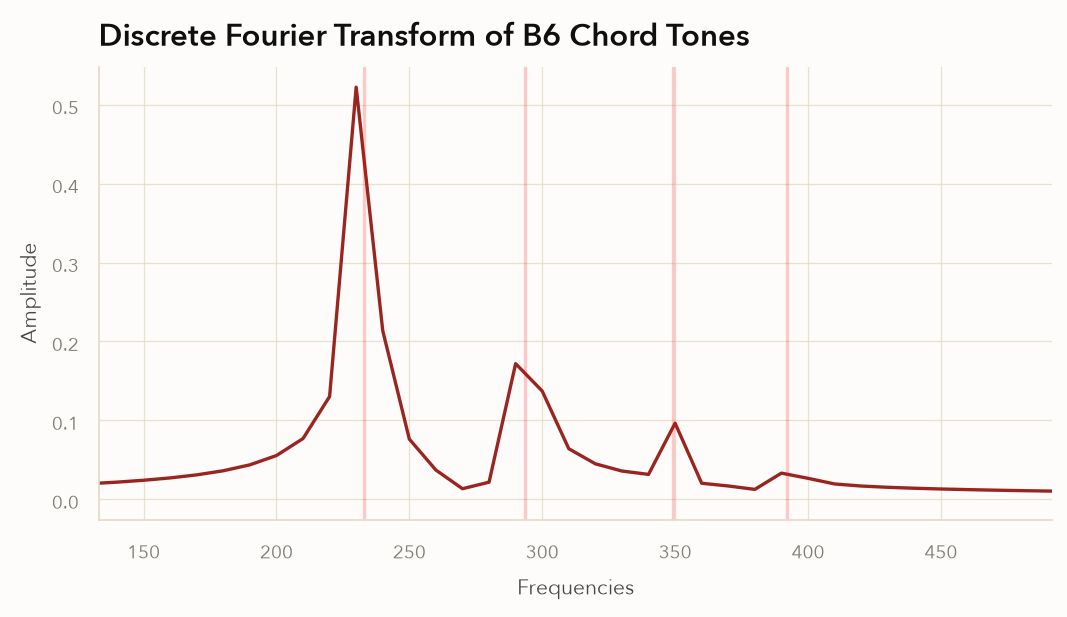

In [22]:
# amps is complex; plot magnitudes
plt.plot(plot_frequencies, np.abs(amps))
plt.xlim(min(bm6_freqs) - 100, max(bm6_freqs) + 100)
plt.title("Discrete Fourier Transform of B6 Chord Tones")
plt.ylabel("Amplitude")
plt.xlabel("Frequencies")

for freq in bm6_freqs:
    plt.axvline(x=freq, linestyle='-', alpha=0.2, color='red')

This is a plot of the relative amplitudes of the constituent frequencies of our chord tone, with vertical bars at the frequencies we used to recreate it.

Lo: A perfect analysis of the sound we sent it.

This thing has a name: We've implemented the [discrete Fourier transform](https://en.wikipedia.org/wiki/Discrete_Fourier_transform), or DFT.

It's arguably the most important technology of the modern era—and surely one of the deepest ideas.

This technically answers the question we started with: _Can we see the frequencies within a sound?_

**Yes**—we can. Somewhat shockingly, we don't need to invert the source-filter approach at all; our solution works against the synthesized vowel, as well.

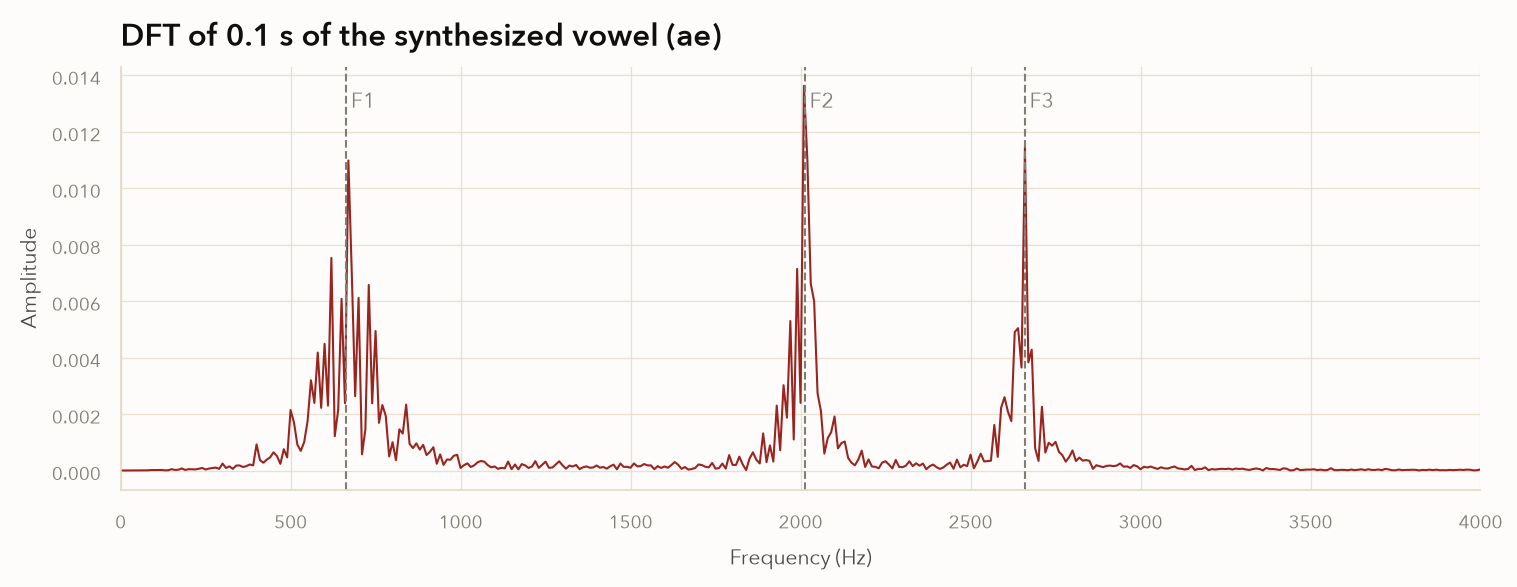

In [23]:
#| code-fold: true
# AI-generated demo (disclosed in _notes/edit-index-2026-11-09.md):
# the bandpass-filtered noise vowel from earlier, 0.1 s of it, through the same SimpleAnalyzer.
import scipy.signal

rng = np.random.default_rng(0)
fs_v = 44100
noise_v = rng.uniform(-1, 1, int(0.1 * fs_v))
formants_v = df.iloc[0][['f1_ss', 'f2_ss', 'f3_ss']].values.astype(float)

vowel_v = np.zeros_like(noise_v)
for freq, bw in zip(formants_v, [130.0, 70.0, 60.0]):        # same bandwidths as the filterbank above
    b, a = scipy.signal.iirpeak(freq, freq / bw, fs=fs_v)
    vowel_v += scipy.signal.filtfilt(b, a, noise_v)

amps_v = SimpleAnalyzer(vowel_v).analyze()
freqs_v = np.arange(len(vowel_v)) * fs_v / len(vowel_v)

fig, ax = plt.subplots(figsize=(10, 3.8))
ax.plot(freqs_v, np.abs(amps_v), lw=1)
for name, freq in zip(['F1', 'F2', 'F3'], formants_v):
    ax.axvline(freq, color=PALETTE["muted"], ls="--", lw=1)
    ax.text(freq, ax.get_ylim()[1] * 0.95, f" {name}", color=PALETTE["muted"], va="top")
ax.set(xlim=(0, 4000), title=f"DFT of 0.1 s of the synthesized vowel ({df.iloc[0]['vowel']})",
       xlabel="Frequency (Hz)", ylabel="Amplitude")
plt.show()

One hiccup. Our formant data contains frequencies measured at 20%, 50%, and 80% development, as well as steady state. Our analysis function shows us which frequencies are in the sound...But does not tell us when they occur. Information about the sequence of frequencies that characterize each formant are completely lost.

It wasn't obvious that would happen, but we'll need a way to recover that.

The solution: Chop the input signal into frames, analyze each frame, and inspect the spectrum of each result to see which frequencies occurred during that specific window of time.

This is the [Short Time Fourier Transform](https://en.wikipedia.org/wiki/Short-time_Fourier_transform), and we'll implement it next time. To do so, we'll need the Fast Fourier Transform, first.

## Fast Fourier Transform

Our analysis function is good enough to prove a point. But it'll break catastrophically if we try to use it for what we set out to do.

Our implementation above is $O(n^{2})$, and it's well-known that quadratic time is impractical.

Ideally, we'd find a $O(N \log N)$ algorithm.

Whenever faced with a quadratic algorithm, we should instinctively search for a [divide and conquer](https://en.wikipedia.org/wiki/Divide-and-conquer_algorithm) solution; recursive implementations often achieve the linearithmic bound.

The FFT has such a well-known solution, called the [Cooley-Tukey algorithm](https://en.wikipedia.org/wiki/Cooley–Tukey_FFT_algorithm).

It's based on the Danielson-Lanczos lemma, provided by Allen Downey in [Think DSP 2](https://allendowney.github.io/ThinkDSP2/chap07.html#dft) as follows:

> The key to the FFT is the Danielson-Lanczos lemma:
>
> $DFT(y)[n] = DFT(e)[n] + \exp(-2 \pi i n / N) DFT(o)[n]$
>
> Where $DFT(y)[n]$ is the $n$th element of the DFT of $y$; $e$ is the even elements of $y$, and $o$ is the odd elements of $y$.
>
> This lemma suggests a recursive algorithm for the DFT:
>
> 1. Given a wave array, $y$, split it into its even elements, $e$, and its odd elements, $o$.
>
> 2. Compute the DFT of $e$ and $o$ by making recursive calls.
>
> 3. Compute $DFT(y)$ for each value of $n$ using the Danielson-Lanczos lemma.

In [24]:
# AI-generated implementation (disclosed in _notes/edit-index-2026-11-09.md).
# Radix-2 Cooley-Tukey; len(ys) must be a power of 2.
def fft(ys):
    ys = np.asarray(ys, dtype=complex)
    N = len(ys)
    if N == 1:
        return ys

    E = fft(ys[0::2])        # DFT of the even-indexed samples, length N/2
    O = fft(ys[1::2])        # DFT of the odd-indexed samples, length N/2

    k = np.arange(N // 2)
    W = np.exp(-2j * np.pi * k / N)   # twiddle factors

    # Danielson-Lanczos, written out for both halves of the output.
    # E and O repeat with period N/2, and W shifted by N/2 flips sign:
    #   X[k]       = E[k] + W[k] O[k]
    #   X[k + N/2] = E[k] - W[k] O[k]
    return np.concatenate([E + W * O, E - W * O])

In [25]:
# AI-generated check (disclosed in _notes/edit-index-2026-11-09.md):
# run our fft on a real Hillenbrand recording and compare against NumPy.
import time

y, sr_y = lb.load(f"{df['path'].iloc[0]}.wav", sr=None)
N_pad = 1 << int(np.ceil(np.log2(len(y))))          # next power of 2
y_pad = np.pad(y, (0, N_pad - len(y)))               # zero-pad to N_pad samples

t0 = time.perf_counter(); ours = fft(y_pad); t_ours = time.perf_counter() - t0
t0 = time.perf_counter(); ref = np.fft.fft(y_pad); t_np = time.perf_counter() - t0
print(f"{len(y)} samples at {sr_y} Hz, zero-padded to {N_pad}")
print(f"matches np.fft.fft: {np.allclose(ours, ref)}  (max abs diff {np.max(np.abs(ours - ref)):.2e})")
print(f"our fft: {t_ours * 1000:.1f} ms   np.fft.fft: {t_np * 1000:.2f} ms")

# the quadratic version, on a 4096-sample slice only (it builds a 4096 x 4096 matrix)
s = y_pad[:4096]
t0 = time.perf_counter(); slow = SimpleAnalyzer(s).analyze() * len(s); t_slow = time.perf_counter() - t0
t0 = time.perf_counter(); fast = fft(s); t_fast = time.perf_counter() - t0
print(f"4096 samples: SimpleAnalyzer {t_slow * 1000:.0f} ms vs our fft {t_fast * 1000:.1f} ms; "
      f"same result: {np.allclose(slow, fast)}")

10730 samples at 16000 Hz, zero-padded to 16384
matches np.fft.fft: True  (max abs diff 1.40e-05)
our fft: 38.5 ms   np.fft.fft: 1.42 ms
4096 samples: SimpleAnalyzer 209 ms vs our fft 13.3 ms; same result: True


We won't belabor the point; from now on, we'll use [NumPy's fft](https://numpy.org/doc/stable/reference/routines.fft.html#module-numpy.fft) anyway.

The point is: This is possible, and makes it fast enough to use.

Watch the [Reducible video on the FFT](https://www.youtube.com/watch?v=h7apO7q16V0) for a proper exposition.